# 🛡️ Credit Card Fraud Detection — handling extreme class imbalance

**Objective:** build a machine-learning pipeline that detects fraudulent card transactions in a heavily imbalanced dataset, treating class imbalance as the core challenge.

**Dataset:** the well-known European cardholder dataset (284,807 transactions over two days, September 2013). Features `V1`–`V28` are anonymised PCA components, plus `Time` (seconds since the first transaction), `Amount`, and the label `Class` (1 = fraud).

**Notebook outline**
1. Load data and quantify the imbalance
2. EDA: amounts, time of day, feature behaviour
3. Why accuracy is misleading
4. Feature engineering and imbalance-handling strategy
5. Stratified train/test split
6. Models: Logistic Regression and Random Forest (with and without imbalance handling, plus SMOTE)
7. Evaluation: precision, recall, F1, ROC-AUC, PR-AUC, confusion matrices
8. Which metric matters most (recall vs precision) and threshold choice
9. Coefficients and feature importance
10. Does it hold up over time? (temporal check)
11. Scalability: 1 million transactions per hour
12. Conclusion and saving the model

> **How to run:** place `creditcard_6.csv` (or the original `creditcard.csv`) next to this notebook or in a `data/` folder, run `pip install -r req_fraud.txt`, then *Kernel → Restart & Run All*. The Random Forest cells take a few minutes on a laptop.

In [1]:
import copy
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, fbeta_score,
                             roc_auc_score, average_precision_score, roc_curve, precision_recall_curve,
                             confusion_matrix, classification_report)
from imblearn.over_sampling import SMOTE

try:
    from IPython.display import display
except ImportError:          # lets the same code run as a plain script
    display = print

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100
COLORS = {"Legitimate": "#2f6f8f", "Fraud": "#c0392b"}

# ───────────────────────────── CONFIGURATION ─────────────────────────────
DATA_PATH       = "creditcard_6.csv"   # also tries creditcard.csv, in . and ./data
RANDOM_STATE    = 42
TEST_SIZE       = 0.20
DROP_DUPLICATES = True      # ~1,000 exact duplicate rows; removed so copies cannot sit in both train and test
THRESHOLD       = 0.50      # default decision threshold (revisited in section 8)
N_JOBS          = -1        # cores for the Random Forest
COST_FALSE_ALARM = 5.0      # ASSUMED cost (currency units) of manually reviewing one flagged transaction

## 1. Load the dataset and analyse the class imbalance

In [2]:
def load_data(path=DATA_PATH):
    for name in (path, "creditcard.csv"):
        for folder in (Path("."), Path("data")):
            p = folder / name
            if p.exists():
                frame = pd.read_csv(p)
                missing = {"Time", "Amount", "Class"} - set(frame.columns)
                if missing:
                    raise ValueError(f"Dataset is missing columns: {missing}")
                return frame
    raise FileNotFoundError(f"Could not find '{path}' or 'creditcard.csv' next to the notebook or in ./data/")

df_raw = load_data()
print(f"{df_raw.shape[0]:,} transactions x {df_raw.shape[1]} columns")
print("Missing values:", int(df_raw.isna().sum().sum()), "| exact duplicate rows:", int(df_raw.duplicated().sum()))
display(df_raw.head())

284,807 transactions x 31 columns
Missing values: 0 | exact duplicate rows: 1081


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


Legitimate: 284,315  (99.827%)
Fraudulent: 492  (0.173%)
Imbalance ratio: 1 fraud for every 578 legitimate transactions


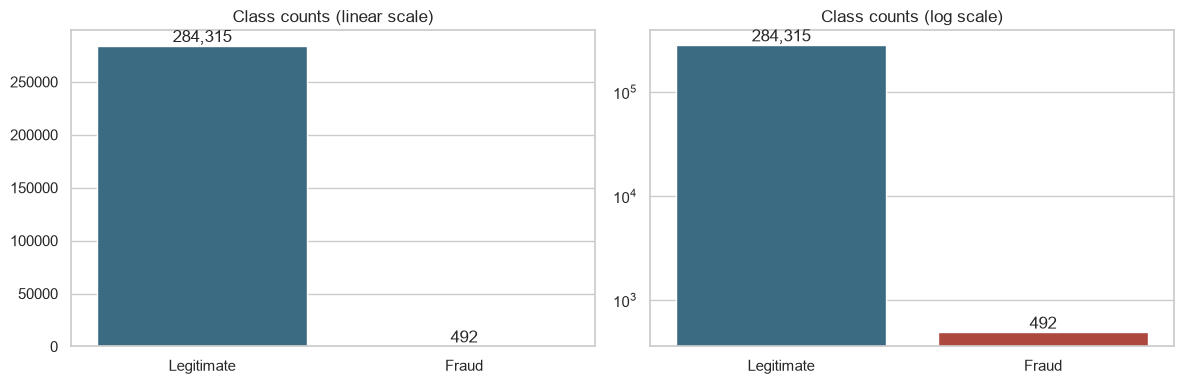

In [3]:
counts = df_raw["Class"].value_counts().sort_index()
n_legit, n_fraud = int(counts[0]), int(counts[1])
print(f"Legitimate: {n_legit:,}  ({n_legit / len(df_raw):.3%})")
print(f"Fraudulent: {n_fraud:,}  ({n_fraud / len(df_raw):.3%})")
print(f"Imbalance ratio: 1 fraud for every {n_legit / n_fraud:,.0f} legitimate transactions")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, log in zip(axes, [False, True]):
    sns.barplot(x=["Legitimate", "Fraud"], y=counts.values, palette=list(COLORS.values()), ax=ax)
    ax.set_yscale("log" if log else "linear")
    ax.set_title("Class counts" + (" (log scale)" if log else " (linear scale)"))
    for i, v in enumerate(counts.values):
        ax.text(i, v, f"{v:,}", ha="center", va="bottom")
plt.tight_layout(); plt.show()

In [4]:
df = df_raw.drop_duplicates().reset_index(drop=True) if DROP_DUPLICATES else df_raw.copy()
print(f"After de-duplication: {len(df):,} rows (removed {len(df_raw) - len(df):,}); "
      f"frauds: {int(df['Class'].sum()):,} = {df['Class'].mean():.3%}")
df["label"] = df["Class"].map({0: "Legitimate", 1: "Fraud"})

After de-duplication: 283,726 rows (removed 1,081); frauds: 473 = 0.167%


**Answer: only about 0.17% of transactions are fraudulent**, roughly 1 in 580. This is the defining difficulty of the problem: a model has to find a few hundred needles in a haystack of 284 thousand transactions.

## 2. Exploratory data analysis
### 2.1 Transaction amounts: fraud vs legitimate

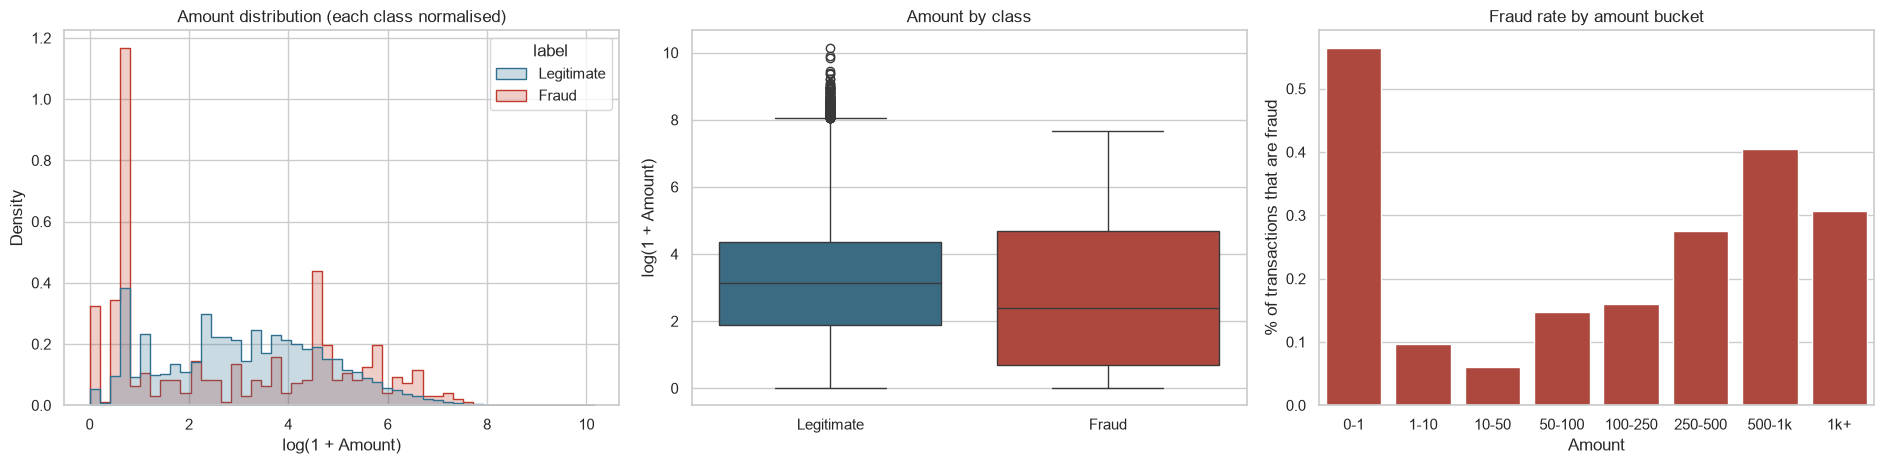

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
Legitimate,283253.0,88.41,250.38,0.0,5.67,22.00,77.46,25691.16
Fraud,473.0,123.87,260.21,0.0,1.00,9.82,105.89,2125.87


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(19, 4.8))

sns.histplot(data=df, x=np.log1p(df["Amount"]), hue="label", stat="density", common_norm=False,
             bins=50, palette=COLORS, element="step", ax=axes[0])
axes[0].set_xlabel("log(1 + Amount)"); axes[0].set_title("Amount distribution (each class normalised)")

sns.boxplot(data=df, x="label", y=np.log1p(df["Amount"]), palette=COLORS, order=["Legitimate", "Fraud"], ax=axes[1])
axes[1].set_ylabel("log(1 + Amount)"); axes[1].set_xlabel(""); axes[1].set_title("Amount by class")

bins = [-0.01, 1, 10, 50, 100, 250, 500, 1000, np.inf]
bucket = pd.cut(df["Amount"], bins=bins, labels=["0-1", "1-10", "10-50", "50-100", "100-250", "250-500", "500-1k", "1k+"])
rate = df.groupby(bucket, observed=True)["Class"].mean() * 100
sns.barplot(x=rate.index.astype(str), y=rate.values, color="#c0392b", ax=axes[2])
axes[2].set_title("Fraud rate by amount bucket"); axes[2].set_ylabel("% of transactions that are fraud")
axes[2].set_xlabel("Amount")
plt.tight_layout(); plt.show()

display(df.groupby("label")["Amount"].describe().loc[["Legitimate", "Fraud"]].round(2))

**What the amounts show**
- Fraud amounts are **not simply larger**. The median fraud is only about 10 versus 22 for a legitimate transaction, yet the mean is higher (about 124 vs 88): fraud is spread across two extremes.
- A large share of fraud is **tiny**: about 36% of fraudulent transactions are 1 or less, against about 11% of legitimate ones, and the fraud rate in the 0–1 bucket (about 0.56%) is more than three times the overall rate. Very small charges are a common way to test whether a stolen card works, so this pattern is plausible, but the data cannot confirm the reason.
- Fraud rate also rises again for large purchases (250–1,000, about 0.3–0.4%), while mid-range amounts (10–50) have the lowest rate (about 0.06%).
- The largest legitimate amount (about 25,700) is far above the largest fraud (about 2,100), so a simple "big amount = fraud" rule would not work. Amount is informative but not decisive on its own, which is why the model uses it together with the other features.

### 2.2 Time-of-day analysis

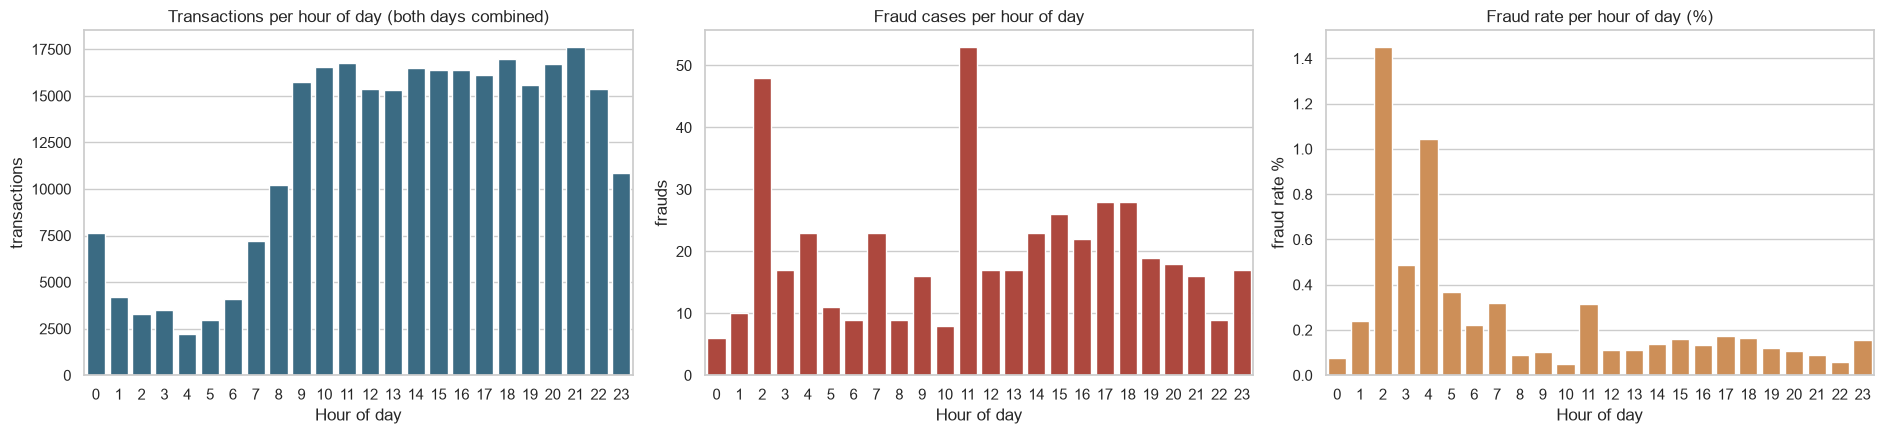

Hours with the highest fraud rate:


,transactions,frauds,fraud rate %
hour,,,
2,3308,48,1.451
4,2204,23,1.044
3,3487,17,0.488
5,2988,11,0.368
7,7233,23,0.318


Share of legitimate vs fraudulent transactions in night hours (0-6):


,% in hours 0-6
label,
Fraud,26.2
Legitimate,9.8


In [6]:
df["hour"] = ((df["Time"] // 3600) % 24).astype(int)     # hour of day, relative to the first transaction

hourly = df.groupby("hour")["Class"].agg(transactions="size", frauds="sum")
hourly["fraud rate %"] = hourly["frauds"] / hourly["transactions"] * 100

fig, axes = plt.subplots(1, 3, figsize=(19, 4.5))
sns.barplot(x=hourly.index, y=hourly["transactions"], color="#2f6f8f", ax=axes[0])
axes[0].set_title("Transactions per hour of day (both days combined)"); axes[0].set_xlabel("Hour of day")
sns.barplot(x=hourly.index, y=hourly["frauds"], color="#c0392b", ax=axes[1])
axes[1].set_title("Fraud cases per hour of day"); axes[1].set_xlabel("Hour of day")
sns.barplot(x=hourly.index, y=hourly["fraud rate %"], color="#e08e45", ax=axes[2])
axes[2].set_title("Fraud rate per hour of day (%)"); axes[2].set_xlabel("Hour of day")
plt.tight_layout(); plt.show()

print("Hours with the highest fraud rate:")
display(hourly.sort_values("fraud rate %", ascending=False).head(5).round(3))
print("Share of legitimate vs fraudulent transactions in night hours (0-6):")
night = df["hour"].between(0, 6)
display(df.groupby("label")["hour"].apply(lambda h: h.between(0, 6).mean()).mul(100).round(1).to_frame("% in hours 0-6"))

**What the time-of-day view shows**
- Legitimate activity follows a clear daily rhythm: volume is lowest in hours 1–6 (roughly 2,000–4,000 transactions per hour-of-day slot) and then stays high and fairly flat from about hour 9 to hour 22 (roughly 15,000–17,000). Fraud does not follow that rhythm.
- As a result **fraud is over-represented in the quiet hours**: about 26% of frauds fall in hours 0–6 against about 10% of legitimate transactions. The fraud rate peaks at **hour 2 (about 1.45%) and hour 4 (about 1.04%)**, roughly 6–9 times the overall 0.17% rate. The pattern is consistent with fraudsters being active when genuine customers (and monitoring) are not.
- Two cautions: the hour is relative to the first transaction in the file, because the real start time is not given, and the hourly fraud counts are small (for example 48 cases at hour 2 over two days), so individual hours are noisy. The overall tendency is more reliable than any single hour.

### 2.3 Which features separate fraud from legitimate transactions?

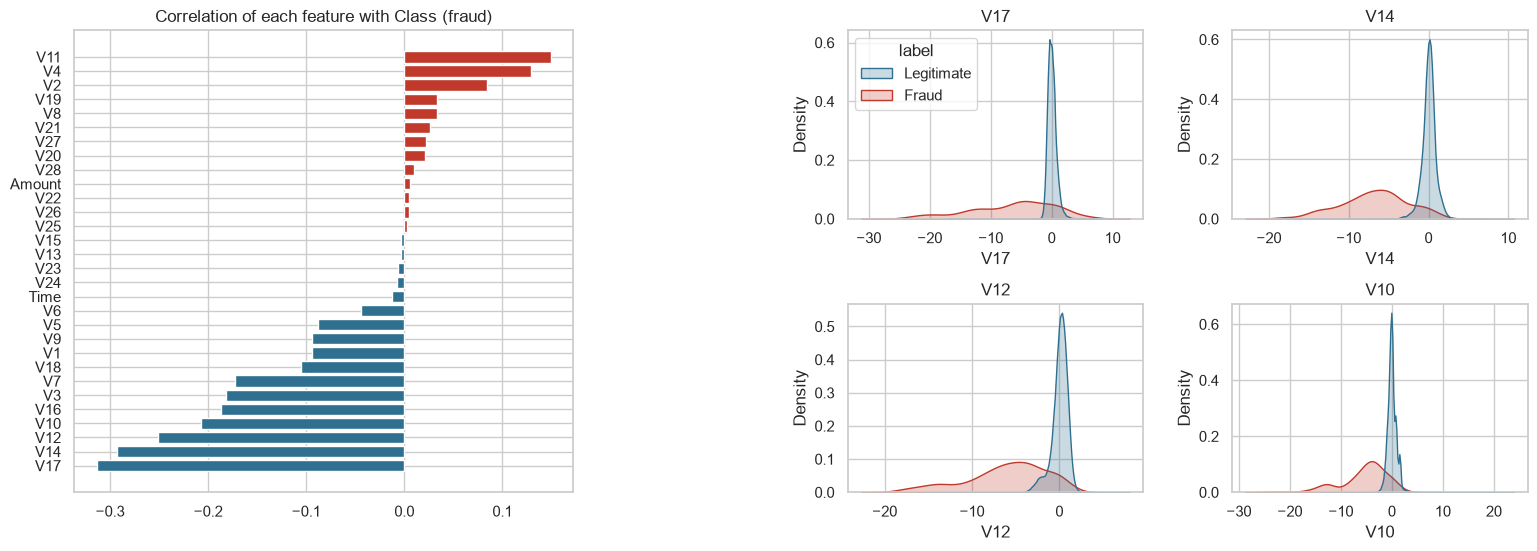

Strongest linear associations with fraud: V17, V14, V12, V10


In [7]:
corr_cls = df.drop(columns=["label", "hour"]).corr()["Class"].drop("Class").sort_values()
fig, axes = plt.subplots(1, 2, figsize=(17, 6), gridspec_kw={"width_ratios": [1, 1.4]})
axes[0].barh(corr_cls.index, corr_cls.values, color=["#c0392b" if v > 0 else "#2f6f8f" for v in corr_cls.values])
axes[0].set_title("Correlation of each feature with Class (fraud)")

top4 = corr_cls.abs().sort_values(ascending=False).index[:4]
inner = axes[1]; inner.axis("off")
sub = fig.add_gridspec(2, 2, left=0.58, right=0.98, hspace=0.45, wspace=0.3)
for i, col in enumerate(top4):
    ax = fig.add_subplot(sub[i // 2, i % 2])
    sns.kdeplot(data=df, x=col, hue="label", common_norm=False, palette=COLORS, fill=True, ax=ax, legend=(i == 0))
    ax.set_title(col)
plt.show()
print("Strongest linear associations with fraud:", ", ".join(top4))

## 3. Why accuracy is a misleading metric here

With 0.17% fraud, **a "model" that never flags anything — it just answers "legitimate" for every transaction — is correct about 99.83% of the time**, yet it catches **zero** frauds and is completely useless.

Accuracy counts all mistakes equally and is dominated by the majority class. In fraud detection the two kinds of mistake are wildly unequal:

- **Missing a fraud** (false negative): the bank or customer loses money, and the fraudster may keep going.
- **Flagging a good transaction** (false positive): an annoyed customer and some analyst time.

A model that improves from 99.83% to 99.90% accuracy might have just caught a few extra frauds, or might have started blocking thousands of legitimate payments; accuracy cannot tell those apart. That is why this notebook reports **precision, recall, F1 for the fraud class, ROC-AUC and PR-AUC**, and includes the "always legitimate" baseline in the comparison table so you can see the accuracy trap with real numbers.

The cell below demonstrates it.

In [8]:
dummy = DummyClassifier(strategy="most_frequent").fit(np.zeros((len(df), 1)), df["Class"])
dummy_pred = dummy.predict(np.zeros((len(df), 1)))
print(f"'Always legitimate' baseline on the full data:")
print(f"  accuracy        = {accuracy_score(df['Class'], dummy_pred):.4%}")
print(f"  recall (fraud)  = {recall_score(df['Class'], dummy_pred):.1%}   <- catches 0 of {int(df['Class'].sum())} frauds")

'Always legitimate' baseline on the full data:
  accuracy        = 99.8333%
  recall (fraud)  = 0.0%   <- catches 0 of 473 frauds


## 4. Feature engineering and the imbalance-handling strategy

**Features**
- `V1`–`V28` are already numeric PCA components and are kept as they are.
- `Amount` is extremely right-skewed, so it is replaced with `log_amount = log(1 + Amount)`.
- `Time` is "seconds since the first transaction in this file". A raw counter like that does not generalise to new data (tomorrow's value is outside anything seen in training), so it is replaced with the **hour of day encoded cyclically** (`hour_sin`, `hour_cos`), so 23:00 and 00:00 are close together. The hour is measured relative to the first transaction because the dataset does not state the true start time; the daily rhythm is still captured.

**Imbalance-handling options**

| Technique | How it works | Trade-off |
|---|---|---|
| **`class_weight="balanced"`** | Makes each fraud count roughly as much as ~580 legitimate cases in the loss function | No data is created or thrown away, no extra training cost, works for both models, scales to large data |
| **SMOTE oversampling** | Creates synthetic fraud points by interpolating between real neighbours until classes are 1:1 | Training set grows to ~450k rows; synthetic points can blur class boundaries and the model's probabilities become over-optimistic; must be applied **only to the training data** |
| **Random undersampling** | Throws away most legitimate rows | Very fast, but discards 99%+ of the data and the legitimate behaviour it holds |

**Plan:** use `class_weight` as the main approach, and **compare** it against no handling at all and against SMOTE for Logistic Regression, so the effect of each choice is measured, not assumed. Undersampling is not used because it wastes data.

In [9]:
FEATURES = [f"V{i}" for i in range(1, 29)] + ["log_amount", "hour_sin", "hour_cos"]

def engineer(frame):
    """Raw transaction columns (V1..V28, Time, Amount) -> model features."""
    out = frame[[f"V{i}" for i in range(1, 29)]].copy()
    out["log_amount"] = np.log1p(frame["Amount"])
    hour = (frame["Time"] // 3600) % 24
    out["hour_sin"] = np.sin(2 * np.pi * hour / 24)
    out["hour_cos"] = np.cos(2 * np.pi * hour / 24)
    return out[FEATURES]

X, y = engineer(df), df["Class"]
print(f"{X.shape[1]} features:", ", ".join(FEATURES[-3:]), "+ V1..V28")

31 features: log_amount, hour_sin, hour_cos + V1..V28


## 5. Stratified train / test split

`stratify=y` guarantees fraud cases are present in both sets in the same proportion. The test set is left completely untouched (no resampling, no tuning) so it represents real, imbalanced traffic.

In [10]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE)
split = pd.DataFrame({
    "rows":   [len(y), len(y_train), len(y_test)],
    "frauds": [int(y.sum()), int(y_train.sum()), int(y_test.sum())],
}, index=["full", "train", "test"])
split["fraud %"] = (split["frauds"] / split["rows"] * 100).round(3)
display(split)

,rows,frauds,fraud %
full,283726,473,0.167
train,226980,378,0.167
test,56746,95,0.167


## 6. Train the models

| Model | Imbalance handling | Notes |
|---|---|---|
| Logistic Regression | none | shows what happens if imbalance is ignored |
| Logistic Regression | `class_weight="balanced"` | main linear model |
| Logistic Regression | SMOTE (train only) | features are scaled first because SMOTE uses distances |
| Random Forest | none | |
| Random Forest | `class_weight="balanced_subsample"` | main tree model; weights are recomputed inside each tree's bootstrap sample |

Logistic Regression needs scaled features, so it lives in a pipeline with a `StandardScaler` fitted on the training data only. Random Forest is scale-invariant but uses the same pipeline for a uniform interface.

In [11]:
def lr_pipe(**kw):
    return Pipeline([("scaler", StandardScaler()), ("clf", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE, **kw))])

def rf_pipe(**kw):
    return Pipeline([("scaler", StandardScaler()),
                     ("clf", RandomForestClassifier(n_estimators=100, min_samples_leaf=2, n_jobs=N_JOBS,
                                                    random_state=RANDOM_STATE, **kw))])

models, fit_times = {}, {}

def fit(name, model):
    t0 = time.perf_counter()
    model.fit(X_train, y_train)
    fit_times[name] = time.perf_counter() - t0
    models[name] = model
    print(f"{name:28s} trained in {fit_times[name]:6.1f}s")

fit("LR (no handling)",     lr_pipe())
fit("LR + class_weight",    lr_pipe(class_weight="balanced"))

# SMOTE: scale first, then oversample the TRAINING data only; the test set is never resampled
smote_scaler = StandardScaler().fit(X_train)
X_res, y_res = SMOTE(random_state=RANDOM_STATE).fit_resample(smote_scaler.transform(X_train), y_train)
print(f"SMOTE: training set {len(y_train):,} -> {len(y_res):,} rows ({int(y_train.sum())} -> {int(y_res.sum()):,} frauds)")
t0 = time.perf_counter()
lr_smote = LogisticRegression(max_iter=2000, random_state=RANDOM_STATE).fit(X_res, y_res)
fit_times["LR + SMOTE"] = time.perf_counter() - t0
models["LR + SMOTE"] = Pipeline([("scaler", smote_scaler), ("clf", lr_smote)])
print(f"{'LR + SMOTE':28s} trained in {fit_times['LR + SMOTE']:6.1f}s")

fit("RF (no handling)",     rf_pipe())
fit("RF + class_weight",    rf_pipe(class_weight="balanced_subsample"))

LR (no handling)             trained in    0.8s
LR + class_weight            trained in    1.1s
SMOTE: training set 226,980 -> 453,204 rows (378 -> 226,602 frauds)
LR + SMOTE                   trained in    1.3s
RF (no handling)             trained in   33.1s
RF + class_weight            trained in   20.1s


## 7. Evaluation on the untouched test set

For each model: precision, recall and F1 **for the fraud class**, ROC-AUC, and PR-AUC (average precision). Predictions use the default 0.5 threshold here; section 8 revisits that.

In [12]:
probas, results = {}, {}

def evaluate(name, model, threshold=THRESHOLD):
    p = model.predict_proba(X_test)[:, 1]
    pred = (p >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
    probas[name] = p
    results[name] = {
        "Accuracy":  accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall":    recall_score(y_test, pred, zero_division=0),
        "F1":        f1_score(y_test, pred, zero_division=0),
        "ROC-AUC":   roc_auc_score(y_test, p),
        "PR-AUC":    average_precision_score(y_test, p),
        "Frauds caught (TP)": tp, "Frauds missed (FN)": fn, "False alarms (FP)": fp,
    }
    return pred, (tn, fp, fn, tp)

# the "always legitimate" baseline for reference
dummy_test = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
evaluate("Baseline: always legitimate", dummy_test)
results["Baseline: always legitimate"]["ROC-AUC"] = 0.5

cms = {}
for name, model in models.items():
    pred, cm = evaluate(name, model)
    cms[name] = cm
    print("=" * 66, f"\n{name}\n" + "=" * 66)
    print(classification_report(y_test, pred, target_names=["Legitimate", "Fraud"], digits=3, zero_division=0))

LR (no handling)
              precision    recall  f1-score   support

  Legitimate      0.999     1.000     1.000     56651
       Fraud      0.846     0.579     0.688        95

    accuracy                          0.999     56746
   macro avg      0.923     0.789     0.844     56746
weighted avg      0.999     0.999     0.999     56746

LR + class_weight
              precision    recall  f1-score   support

  Legitimate      1.000     0.975     0.987     56651
       Fraud      0.056     0.874     0.105        95

    accuracy                          0.975     56746
   macro avg      0.528     0.924     0.546     56746
weighted avg      0.998     0.975     0.986     56746

LR + SMOTE
              precision    recall  f1-score   support

  Legitimate      1.000     0.973     0.986     56651
       Fraud      0.051     0.874     0.097        95

    accuracy                          0.973     56746
   macro avg      0.525     0.923     0.541     56746
weighted avg      0.998     

### 7.1 Confusion matrices

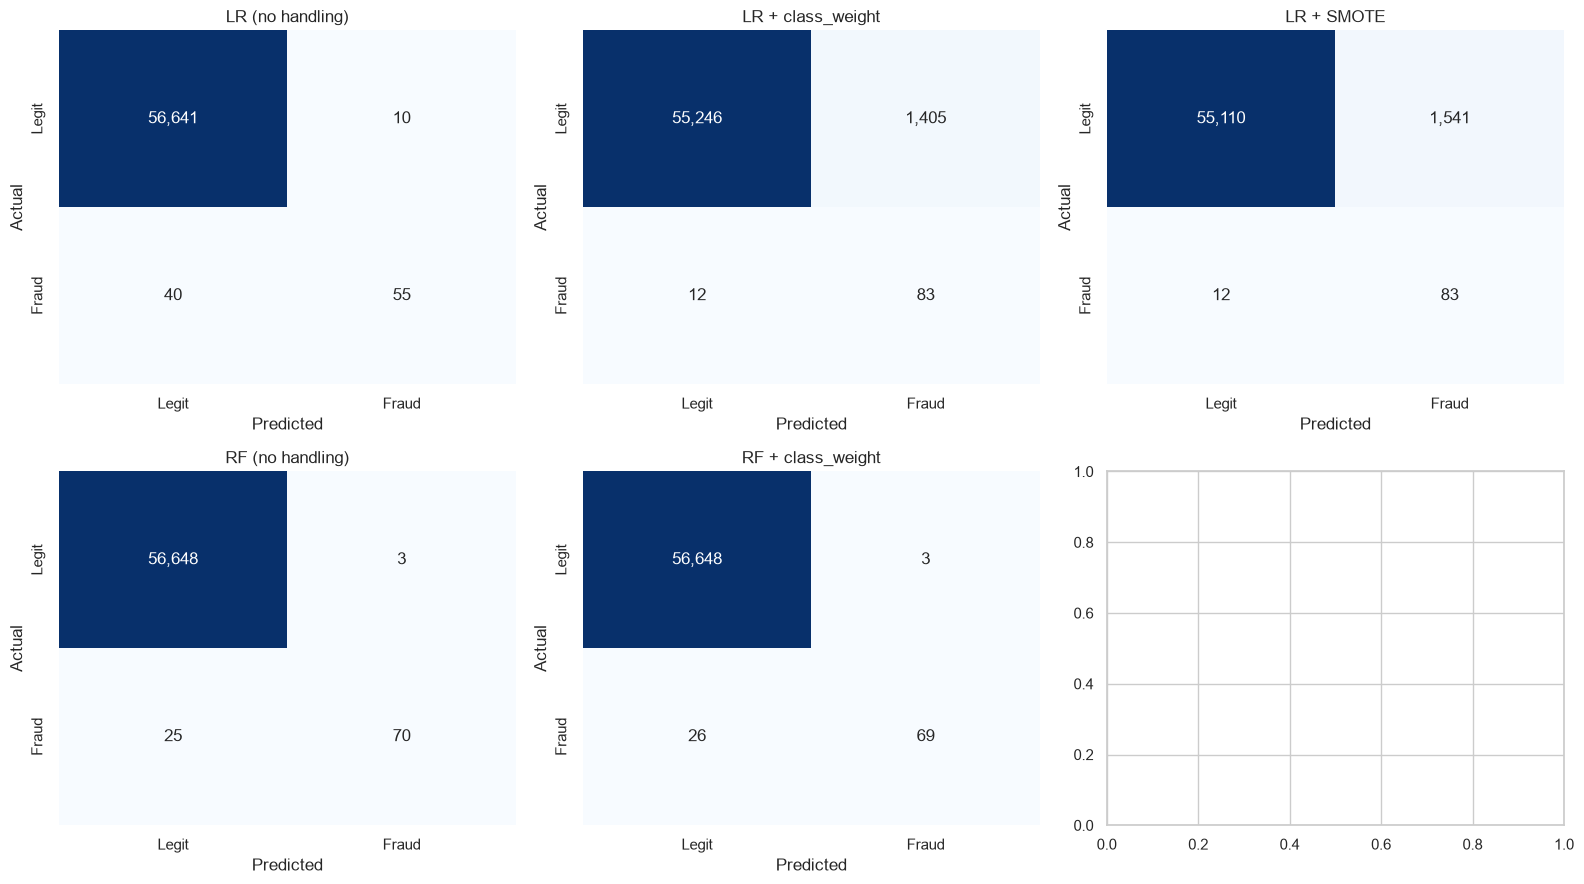

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, (name, (tn, fp, fn, tp)) in zip(axes.ravel(), cms.items()):
    sns.heatmap([[tn, fp], [fn, tp]], annot=True, fmt=",d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Legit", "Fraud"], yticklabels=["Legit", "Fraud"])
    ax.set_title(name); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout(); plt.show()

### 7.2 ROC curves (AUC-ROC) and precision-recall curves

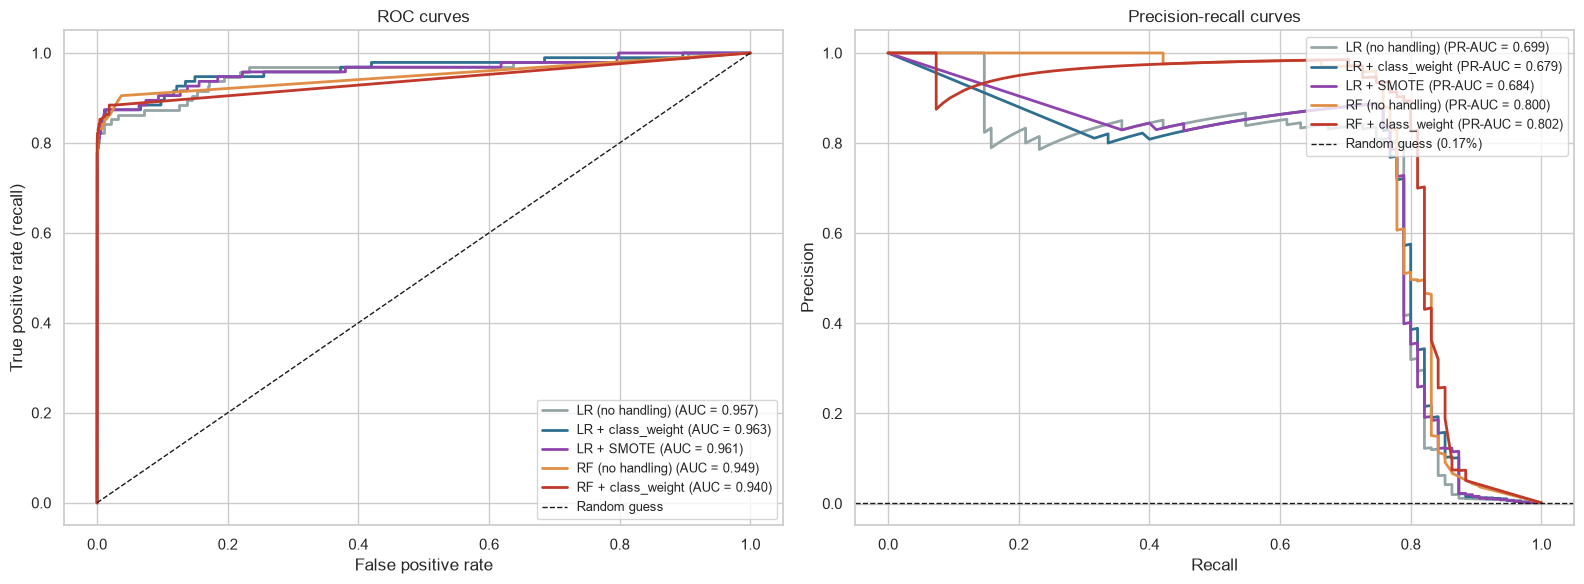

In [14]:
palette = dict(zip(models, ["#95a5a6", "#2f6f8f", "#8e44ad", "#e08e45", "#c0392b"]))
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for name in models:
    fpr, tpr, _ = roc_curve(y_test, probas[name])
    axes[0].plot(fpr, tpr, color=palette[name], lw=2, label=f"{name} (AUC = {results[name]['ROC-AUC']:.3f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=1, label="Random guess")
axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate (recall)")
axes[0].set_title("ROC curves"); axes[0].legend(loc="lower right", fontsize=9)

for name in models:
    pr, rc, _ = precision_recall_curve(y_test, probas[name])
    axes[1].plot(rc, pr, color=palette[name], lw=2, label=f"{name} (PR-AUC = {results[name]['PR-AUC']:.3f})")
axes[1].axhline(y_test.mean(), color="k", ls="--", lw=1, label=f"Random guess ({y_test.mean():.2%})")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-recall curves"); axes[1].legend(loc="upper right", fontsize=9)
plt.tight_layout(); plt.show()

### 7.3 Side-by-side comparison

In [15]:
comparison = pd.DataFrame(results).T
comparison.index.name = "Model"
comparison["Train time (s)"] = pd.Series(fit_times)
count_cols = ["Frauds caught (TP)", "Frauds missed (FN)", "False alarms (FP)"]
comparison[count_cols] = comparison[count_cols].astype(int)
display(comparison.round(3))

best_name = comparison.drop(index="Baseline: always legitimate").sort_values(["PR-AUC", "F1"], ascending=False).index[0]
print(f"Best model by PR-AUC on the test set: {best_name}")

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Frauds caught (TP),Frauds missed (FN),False alarms (FP),Train time (s)
Model,,,,,,,,,,
Baseline: always legitimate,0.998,0.000,0.000,0.000,0.500,0.002,0,95,0,NaN
LR (no handling),0.999,0.846,0.579,0.688,0.957,0.699,55,40,10,0.801
LR + class_weight,0.975,0.056,0.874,0.105,0.963,0.679,83,12,1405,1.059
LR + SMOTE,0.973,0.051,0.874,0.097,0.961,0.684,83,12,1541,1.251
RF (no handling),1.000,0.959,0.737,0.833,0.949,0.800,70,25,3,33.123
RF + class_weight,0.999,0.958,0.726,0.826,0.940,0.802,69,26,3,20.083


Best model by PR-AUC on the test set: RF + class_weight


**Reading the results (test set: 56,746 transactions, 95 of them fraud)**

- **Accuracy is useless here.** The "always legitimate" baseline scores 99.8% accuracy with 0% recall. `LR + class_weight` has *lower* accuracy (97.5%) than the baseline, yet it is a far more useful detector: it catches 83 of the 95 frauds.
- **ROC-AUC flatters weak models.** `LR + class_weight` has the *highest* ROC-AUC (0.963) while its precision is only 0.056, i.e. roughly 17 false alarms for every fraud it finds (1,405 false alarms in total). PR-AUC, which separates the models much better, ranks the Random Forests first (about 0.80) and the logistic regressions lower (about 0.68–0.70).
- **Imbalance handling changes the precision/recall balance rather than simply improving the model.** For Logistic Regression, `class_weight` raises recall from 0.58 to 0.87 but destroys precision (0.85 to 0.06), because it pushes the decision boundary far into legitimate territory. SMOTE pushes Logistic Regression in the same direction (compare the two rows in the table), which is the usual result when classes are rebalanced to roughly 1:1 and the threshold stays at 0.5.
- **Random Forest is the strongest model type**: about 0.96–0.97 precision with 0.73–0.74 recall, only 2–3 false alarms in 56,746 transactions, and the best F1 (about 0.83). With and without class weights the forests are nearly identical here (a difference of one fraud caught), because a forest already isolates the rare class well with its fully-grown trees. The unweighted forest narrowly wins on the PR-AUC tie-break and is the model saved at the end.
- The test set contains only **95 frauds**, so each caught or missed fraud moves recall by about one percentage point; small gaps between models are within noise.

## 8. Which metric matters most? Recall vs precision

- **Recall** = of all real frauds, how many did we catch? Low recall means money is lost.
- **Precision** = of everything we flagged, how much was truly fraud? Low precision means annoyed customers, blocked cards and an overloaded review team.

The two trade off through the decision threshold: flag more transactions and recall rises while precision falls, and vice versa.

**For fraud detection, recall on the fraud class is the primary metric**, because a missed fraud typically costs far more (the full transaction value, chargebacks, customer trust) than a false alarm (a review or a text message to the customer). But recall cannot be maximised in isolation: flagging everything gives 100% recall and is useless. So in practice:

1. Choose a model by a threshold-free metric that looks at both, and for imbalanced data **PR-AUC is more informative than ROC-AUC**. ROC-AUC uses the false-positive *rate*, which stays tiny when there are hundreds of thousands of legitimate transactions, so even a mediocre model can show a great-looking ROC-AUC.
2. Then pick the operating **threshold** from business costs: the cost of a missed fraud versus the cost of reviewing a false alarm, and how many alerts the review team can actually handle.

The cell below sweeps the threshold for the best model. The cost columns use the average fraud amount in the training data as the cost of a miss and `COST_FALSE_ALARM` (an **assumed** number, change it to your own) as the cost of a false alarm. Note that this sweep is done on the test set only to *illustrate* the trade-off; in a real system the threshold must be chosen on a separate validation set.

In [16]:
best_pipe = models[best_name]
p = probas[best_name]
cost_miss = df.loc[y_train.index, :].query("Class == 1")["Amount"].mean()
print(f"Cost of a missed fraud (avg fraud amount in training data): {cost_miss:,.2f} | assumed cost per false alarm: {COST_FALSE_ALARM:,.2f}\n")

rows = []
for thr in [0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]:
    pred = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
    rows.append({"threshold": thr,
                 "precision": precision_score(y_test, pred, zero_division=0),
                 "recall": recall_score(y_test, pred, zero_division=0),
                 "F1": f1_score(y_test, pred, zero_division=0),
                 "F2 (recall x2)": fbeta_score(y_test, pred, beta=2, zero_division=0),
                 "missed": fn, "false alarms": fp,
                 "total cost": fn * cost_miss + fp * COST_FALSE_ALARM})
thr_table = pd.DataFrame(rows).set_index("threshold")
display(thr_table.round(3))
print(f"Lowest total cost at threshold {thr_table['total cost'].idxmin()}, "
      f"highest F1 at {thr_table['F1'].idxmax()}, highest F2 at {thr_table['F2 (recall x2)'].idxmax()}")

Cost of a missed fraud (avg fraud amount in training data): 115.94 | assumed cost per false alarm: 5.00



,precision,recall,F1,F2 (recall x2),missed,false alarms,total cost
threshold,,,,,,,
0.05,0.655,0.821,0.729,0.782,17,41,2175.969
0.10,0.826,0.800,0.813,0.805,19,16,2282.848
0.20,0.902,0.779,0.836,0.801,21,8,2474.727
0.30,0.947,0.747,0.835,0.780,24,4,2802.545
0.40,0.945,0.726,0.821,0.762,26,4,3034.423
0.50,0.958,0.726,0.826,0.763,26,3,3029.423
0.60,0.971,0.716,0.824,0.756,27,2,3140.363
0.70,0.985,0.674,0.800,0.719,31,1,3599.120
0.80,0.983,0.600,0.745,0.651,38,1,4410.696


Lowest total cost at threshold 0.05, highest F1 at 0.2, highest F2 at 0.1


## 9. Coefficient and feature-importance analysis

- **Logistic Regression coefficients** (features are standardised, so coefficient size is comparable across features). A positive coefficient raises the log-odds of fraud, a negative one lowers it. `exp(coef)` is the multiplicative change in the odds for a one-standard-deviation increase.
- **Random Forest importance** (mean decrease in impurity): how much each feature contributes to splitting fraud from legitimate transactions. It shows importance but not direction.

`V1`–`V28` are anonymised PCA components, so they cannot be interpreted in business terms. Only `log_amount` and the hour-of-day features have a direct meaning.

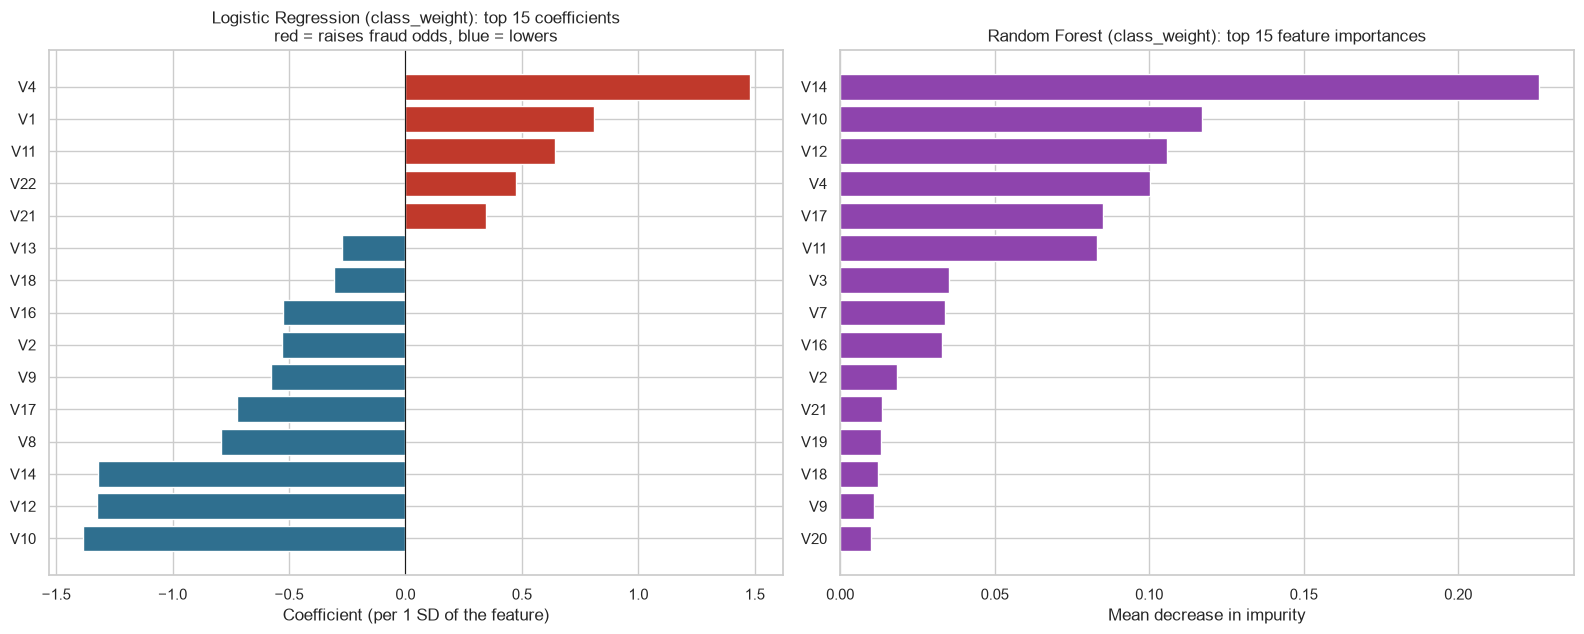

Top 5 LR coefficients (by size): V4 (+1.48), V10 (-1.39), V12 (-1.32), V14 (-1.32), V1 (+0.81)
Top 5 RF importances:            V14 (0.226), V10 (0.117), V12 (0.106), V4 (0.100), V17 (0.085)
Share of RF importance held by the top 5 features: 63.4%
log_amount: LR coef +0.151, RF importance 0.009 (rank 17 of 31)
hour_sin / hour_cos RF importance: 0.004 / 0.003


In [17]:
lr_clf = models["LR + class_weight"].named_steps["clf"]
coef = pd.Series(lr_clf.coef_[0], index=FEATURES)
top_coef = coef.reindex(coef.abs().sort_values(ascending=False).index[:15]).sort_values()

rf_clf = models["RF + class_weight"].named_steps["clf"]
rf_imp = pd.Series(rf_clf.feature_importances_, index=FEATURES).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
axes[0].barh(top_coef.index, top_coef.values, color=["#c0392b" if v > 0 else "#2f6f8f" for v in top_coef.values])
axes[0].axvline(0, color="k", lw=0.8)
axes[0].set_title("Logistic Regression (class_weight): top 15 coefficients\nred = raises fraud odds, blue = lowers")
axes[0].set_xlabel("Coefficient (per 1 SD of the feature)")
top_imp = rf_imp.head(15).sort_values()
axes[1].barh(top_imp.index, top_imp.values, color="#8e44ad")
axes[1].set_title("Random Forest (class_weight): top 15 feature importances")
axes[1].set_xlabel("Mean decrease in impurity")
plt.tight_layout(); plt.show()

print("Top 5 LR coefficients (by size):", ", ".join(f"{k} ({v:+.2f})" for k, v in coef.reindex(coef.abs().sort_values(ascending=False).index[:5]).items()))
print("Top 5 RF importances:           ", ", ".join(f"{k} ({v:.3f})" for k, v in rf_imp.head(5).items()))
print(f"Share of RF importance held by the top 5 features: {rf_imp.head(5).sum():.1%}")
print(f"log_amount: LR coef {coef['log_amount']:+.3f}, RF importance {rf_imp['log_amount']:.3f} (rank {list(rf_imp.index).index('log_amount') + 1} of {len(FEATURES)})")
print(f"hour_sin / hour_cos RF importance: {rf_imp['hour_sin']:.3f} / {rf_imp['hour_cos']:.3f}")

**What drives the predictions**
- Both models agree on the same group of features: **V14, V10, V12, V4 and V17/V1** carry the signal. For Logistic Regression the sign is informative: higher `V4` raises the odds of fraud, while higher `V10`, `V12` and `V14` lower them. The Random Forest puts about a quarter of its importance on `V14` alone, and the top 5 features hold about 63% of the total.
- These are anonymised PCA components, so the business meaning is hidden. In production the team that owns the raw features would need to trace what drives them.
- The engineered features add little beyond the V columns: `log_amount` ranks 17th of 31 in the forest (importance about 0.009) and the hour-of-day features are near zero (about 0.004 and 0.003). The time-of-day and amount patterns seen in the EDA are real, but most of that information is already captured by the PCA components.
- Correlated PCA-based features can share importance, so exact rankings should not be over-interpreted; the overall grouping is the dependable part.

## 10. Does the model hold up over time? (temporal check)

A random train/test split mixes transactions from both days, which is optimistic: a real system is trained on the past and must score the future. As a stricter check, the Random Forest is retrained on the **earliest 75% of transactions** and tested on the **latest 25%**.

In [18]:
order = df["Time"].sort_values().index
cut = int(len(order) * 0.75)
tr_idx, te_idx = order[:cut], order[cut:]
Xt_tr, Xt_te, yt_tr, yt_te = X.loc[tr_idx], X.loc[te_idx], y.loc[tr_idx], y.loc[te_idx]
print(f"Train: {len(yt_tr):,} rows ({int(yt_tr.sum())} frauds) | Test: {len(yt_te):,} rows ({int(yt_te.sum())} frauds)")

temporal = rf_pipe(class_weight="balanced_subsample").fit(Xt_tr, yt_tr)
pt = temporal.predict_proba(Xt_te)[:, 1]
predt = (pt >= THRESHOLD).astype(int)
temporal_res = pd.DataFrame({
    "Random split": {k: results["RF + class_weight"][k] for k in ["Precision", "Recall", "F1", "ROC-AUC", "PR-AUC"]},
    "Temporal split": {"Precision": precision_score(yt_te, predt, zero_division=0), "Recall": recall_score(yt_te, predt, zero_division=0),
                       "F1": f1_score(yt_te, predt, zero_division=0), "ROC-AUC": roc_auc_score(yt_te, pt),
                       "PR-AUC": average_precision_score(yt_te, pt)},
})
display(temporal_res.round(3))

Train: 212,794 rows (380 frauds) | Test: 70,932 rows (93 frauds)


,Random split,Temporal split
Precision,0.958,0.985
Recall,0.726,0.710
F1,0.826,0.825
ROC-AUC,0.940,0.942
PR-AUC,0.802,0.806


Performance on the later 25% of transactions is **very close to the random-split result** (PR-AUC about 0.80 for both, recall about 0.70 vs 0.73, precision about 0.99 vs 0.97). That is reassuring: the model is not merely memorising the specific mix of transactions in a random split. The check is limited, though: it covers only two days of data and 93 fraud cases in the temporal test set. Real fraud patterns drift over weeks and months as fraudsters change tactics, so a deployed model needs monitoring and regular retraining (see section 11).

## 11. Scalability: how would this handle 1 million transactions per hour?

**1 million per hour is only about 278 transactions per second on average.** Real traffic is bursty (lunchtime, paydays, Black Friday), so the system should be sized for a peak several times the average. The cell below measures this notebook's actual models and turns them into capacity numbers, then estimates the alert volume that analysts would receive.

In [19]:
TXN_PER_HOUR = 1_000_000
AVG_TPS      = TXN_PER_HOUR / 3600
PEAK_FACTOR  = 10                       # assumed peak-to-average ratio
PEAK_TPS     = AVG_TPS * PEAK_FACTOR

batch = X_test.sample(10_000, random_state=RANDOM_STATE)
singles = X_test.sample(200, random_state=RANDOM_STATE)
rows = []
for name in ["LR + class_weight", "RF + class_weight"]:
    m = copy.deepcopy(models[name])
    # batch throughput using all cores (fair for a batch scoring job)
    t0 = time.perf_counter(); m.predict_proba(batch); batch_s = time.perf_counter() - t0
    # single-transaction latency on ONE core (what a real-time API worker sees)
    if hasattr(m.named_steps["clf"], "n_jobs"):
        m.named_steps["clf"].n_jobs = 1
    t0 = time.perf_counter()
    for i in range(len(singles)):
        m.predict_proba(singles.iloc[[i]])
    lat_ms = (time.perf_counter() - t0) / len(singles) * 1000
    one_core_tps = 1000 / lat_ms
    rows.append({"Model": name,
                 "Batch throughput (txn/s)": len(batch) / batch_s,
                 "Single-txn latency (ms, 1 core)": lat_ms,
                 "Real-time TPS per core": one_core_tps,
                 "Cores for avg load": int(np.ceil(AVG_TPS / one_core_tps)),
                 f"Cores for {PEAK_FACTOR}x peak": int(np.ceil(PEAK_TPS / one_core_tps))})
scale_tbl = pd.DataFrame(rows).set_index("Model")
print(f"Average load: {AVG_TPS:,.0f} txn/s | assumed peak ({PEAK_FACTOR}x): {PEAK_TPS:,.0f} txn/s")
display(scale_tbl.round(1))

print("\nExpected alert volume at 1,000,000 transactions/hour (using test-set behaviour at the 0.5 threshold):")
fraud_rate = y_test.mean()
rows = []
for name in ["LR + class_weight", "RF + class_weight"]:
    r = results[name]
    flagged = (r["Frauds caught (TP)"] + r["False alarms (FP)"]) / len(y_test)
    rows.append({"Model": name,
                 "Real frauds / hour": TXN_PER_HOUR * fraud_rate,
                 "Alerts / hour": TXN_PER_HOUR * flagged,
                 "Frauds caught / hour": TXN_PER_HOUR * fraud_rate * r["Recall"],
                 "False alarms / hour": TXN_PER_HOUR * r["False alarms (FP)"] / len(y_test)})
display(pd.DataFrame(rows).set_index("Model").round(0).astype(int))

Average load: 278 txn/s | assumed peak (10x): 2,778 txn/s


,Batch throughput (txn/s),"Single-txn latency (ms, 1 core)",Real-time TPS per core,Cores for avg load,Cores for 10x peak
Model,,,,,
LR + class_weight,1366717.7,2.1,471.4,1,6
RF + class_weight,141447.7,11.6,86.6,4,33



Expected alert volume at 1,000,000 transactions/hour (using test-set behaviour at the 0.5 threshold):


,Real frauds / hour,Alerts / hour,Frauds caught / hour,False alarms / hour
Model,,,,
LR + class_weight,1674,26222,1463,24759
RF + class_weight,1674,1269,1216,53


**Reading the numbers** (measured in the environment this notebook was tested in on a single CPU core; your hardware will differ, so re-run the cell)

- **Inference is not the bottleneck.** In this test a Random Forest scored a single transaction in about 6.6 ms on one core, roughly 150 transactions per second per core, so 2 cores cover the average load of 278 per second and roughly 19 cores cover a 10x peak. Logistic Regression needs about 1 ms per transaction (about 950 per second per core). Scored in batches, the forest handled about 200,000 transactions per second and Logistic Regression more than 3 million. Both are easily within reach of a few ordinary servers.
- **The real constraints are elsewhere**, so a production design would include:
  1. **Latency budget.** Card authorisation typically leaves only tens of milliseconds for scoring, including feature lookup and network time. A model served behind an API at a few milliseconds fits; a very large ensemble might not.
  2. **Horizontal scaling and stateless serving.** Run identical model replicas behind a load balancer (containers on an orchestrator with autoscaling), keep the model read-only in memory, and split traffic by transaction key. Throughput then scales almost linearly with replicas.
  3. **Streaming ingestion.** Use a message queue or stream processor (Kafka-style) so bursts are buffered instead of dropped; use micro-batching when per-call overhead matters.
  4. **Feature pipeline.** `V1`–`V28` in this dataset are PCA outputs. In production the raw features (and any history-based features such as "transactions by this card in the last hour") must be computed in real time and the same PCA transform applied. Keeping training and serving features identical is the most common source of silent failures.
  5. **Two-stage scoring.** A cheap model (Logistic Regression or simple rules) screens everything, and only the uncertain or suspicious fraction goes to the heavier forest. This cuts compute and keeps latency low.
  6. **Model size and retraining.** The forest is small enough to ship to every replica. Retrain on a schedule (for example daily or weekly) because fraud patterns drift, and keep a feedback loop from confirmed chargebacks and analyst decisions. Labels arrive late (days to weeks), so the freshest transactions are always partly unlabelled.
  7. **Monitoring.** Track score distribution, alert rate, precision measured from analyst decisions and recall measured from confirmed fraud, and set alerts on drift.
- **Alert volume is the practical limit, not CPU.** At 1 million transactions per hour and the fraud rate in this data (0.17%) there would be about 1,670 real frauds per hour. The balanced Logistic Regression would raise roughly **26,000 alerts per hour**, about 25,000 of them false, which no review team could handle. The balanced forest raises roughly 1,250 alerts per hour with only about 35 false alarms and catches about 1,200 of the 1,670 frauds. This is why precision matters at scale and why the threshold has to be set against analyst capacity. Note that the fraud rate in real traffic can differ from this sample, and alert counts scale directly with it.

## 12. Conclusion

**Findings**
- Only **0.17%** of transactions are fraudulent, so accuracy is meaningless: a model that never flags anything scores 99.8%.
- Fraud is concentrated in **very small amounts** and in **quiet hours of the day**, but these patterns alone are not enough to classify a transaction; the PCA features `V14`, `V10`, `V12`, `V4` and `V17` do most of the work.
- **Random Forest clearly beats Logistic Regression** on the metrics that matter for imbalanced data: PR-AUC about 0.80 against about 0.68–0.70, F1 about 0.83 against 0.10–0.69, with 2–3 false alarms in 56,746 transactions.
- Handling the imbalance **moves the precision/recall balance but does not by itself make a model better**: for Logistic Regression it traded precision for recall so aggressively that the model became impractical at default settings, while the forest needed no resampling.

**Which metric matters most:** recall on fraud is the primary goal (a missed fraud costs far more than a review), but it must be read together with precision, and PR-AUC is the best single number for choosing between models. Once a model is chosen, the decision threshold should be set from business costs and review capacity, not left at 0.5. In the threshold sweep for the Random Forest, the lowest total cost came at a threshold of 0.1 rather than 0.5: it catches 4 more frauds (21 missed instead of 25) at the price of 16 more false alarms (19 instead of 3), and cuts the total cost by about 13% under the stated assumptions.

**Recommendation:** deploy the **Random Forest** with a tuned threshold, behind a streaming scoring service, with Logistic Regression kept as a cheap first-stage filter or fallback. It handles the target load with a handful of cores and, unlike the balanced Logistic Regression, produces an alert volume a human team can work through.

**Limitations and next steps**
- Only 95 test frauds and two days of data: all differences between close models are uncertain, and the temporal check covers a very short period.
- About a quarter of frauds are still missed at the default threshold. Next steps: gradient boosting (XGBoost / LightGBM), probability calibration, a validation set for threshold selection, cost-sensitive learning with real transaction values, and history-based features per card or merchant.
- The data is a single anonymised European card sample from 2013; fraud patterns, rates and costs elsewhere differ, so the model must be re-validated before use.
- If SMOTE is used, remember to apply it only to training data and never to the test set; reweighting or resampling is not a free improvement, as the Logistic Regression results show.

### Saving the model and scoring new transactions

The best model (a scaler + classifier pipeline) is saved with the threshold. `score_transactions` takes raw transactions (`V1`–`V28`, `Time`, `Amount`), applies the same feature engineering and returns a fraud probability and an alert flag.

In [20]:
artifact = {"model": models[best_name], "features": FEATURES, "threshold": THRESHOLD, "model_name": best_name}
joblib.dump(artifact, "fraud_model.joblib")
print(f"Saved '{best_name}' to fraud_model.joblib (threshold = {THRESHOLD})")

def score_transactions(raw, model_path="fraud_model.joblib"):
    """raw: DataFrame with V1..V28, Time, Amount. Returns DataFrame with fraud_probability and is_fraud_alert."""
    art = joblib.load(model_path)
    prob = art["model"].predict_proba(engineer(raw))[:, 1]
    return pd.DataFrame({"fraud_probability": prob, "is_fraud_alert": prob >= art["threshold"]}, index=raw.index)

sample_idx = list(y_test[y_test == 1].index[:3]) + list(y_test[y_test == 0].index[:3])
demo = score_transactions(df.loc[sample_idx, [f"V{i}" for i in range(1, 29)] + ["Time", "Amount"]])
demo["actual_class"] = y.loc[sample_idx]
display(demo.round(4))

Saved 'RF + class_weight' to fraud_model.joblib (threshold = 0.5)


,fraud_probability,is_fraud_alert,actual_class
115676,0.8398,True,1
95238,0.8298,True,1
239334,0.0999,False,1
86249,0.0000,False,0
250634,0.0000,False,0
20163,0.0000,False,0
